<a href="https://colab.research.google.com/github/kunalbobade409-tech/Datheon_Machine_Learning_Data_Science_Internship/blob/main/Multi_Class_Classification_Pipeline_Using_Iris_and_Wine_Datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload your Iris Excel file (.xlsx)


Saving iris_dataset.xlsx to iris_dataset (4).xlsx

First 5 Rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Dataset Shape: (150, 5)

Column Names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Cleaned Dataset Shape: (149, 5)

Species Count:
species
setosa        50
versicolor    50
virginica     49
Name: count, dtype: Int64


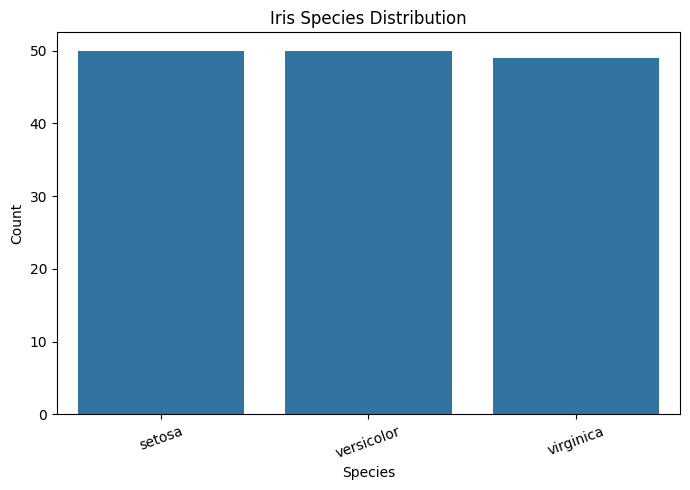

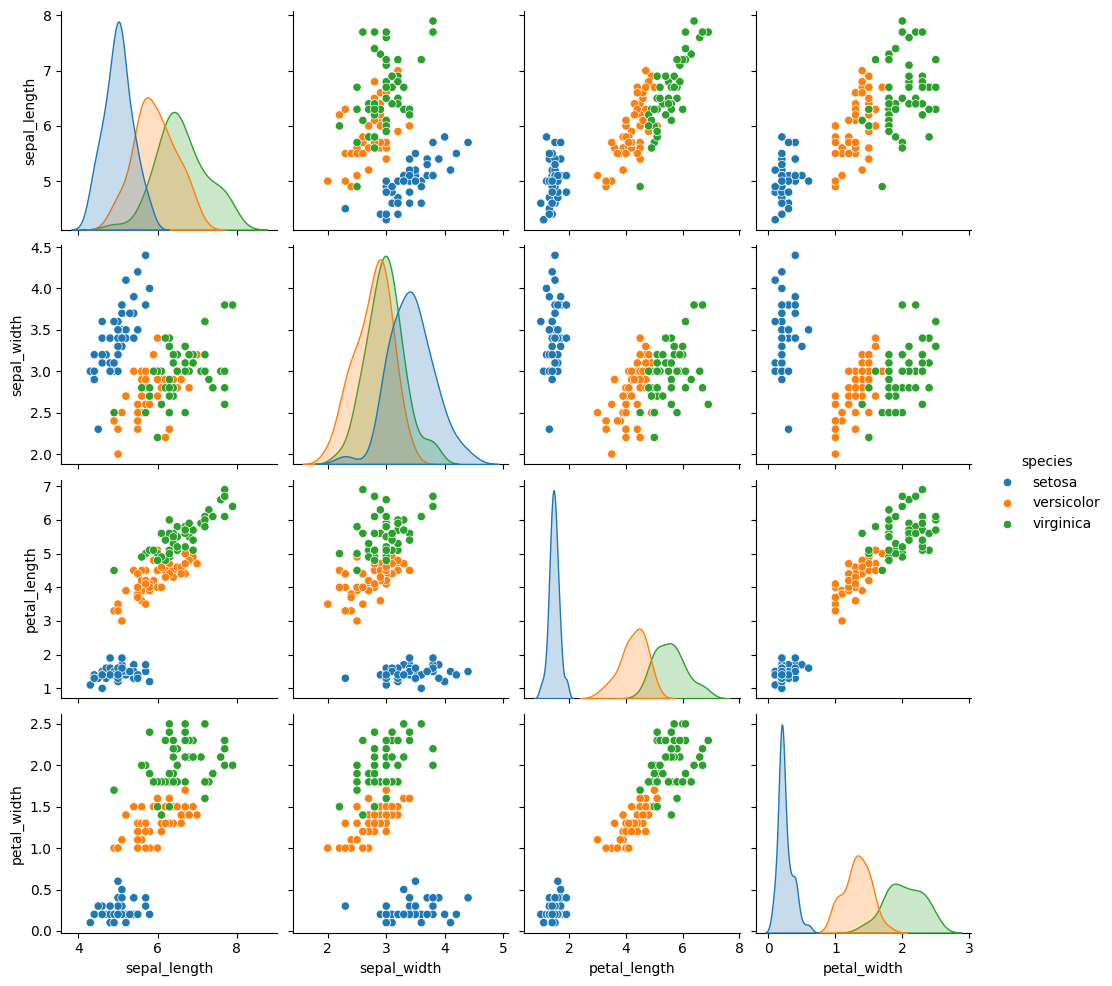

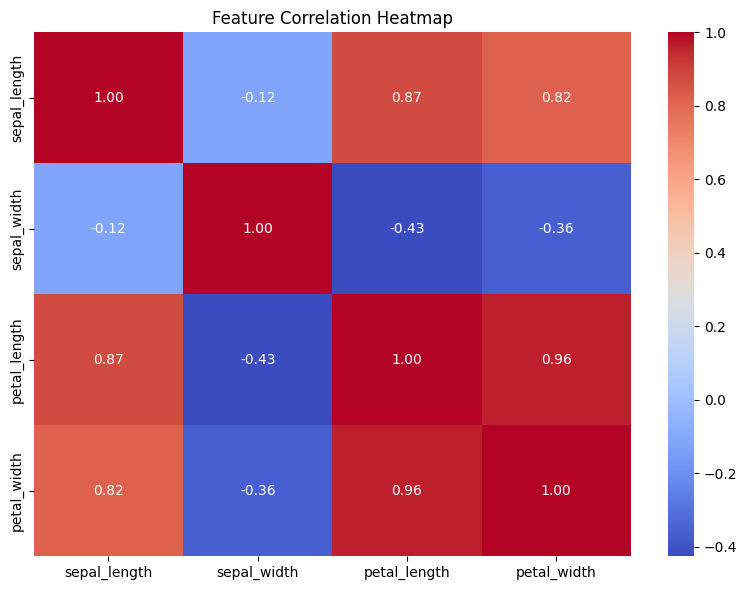


Training Samples: 119
Testing Samples: 30

Classification Report: Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Classification Report: Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Model Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.933,0.933,0.933,0.933
1,Decision Tree,0.933,0.933,0.933,0.933


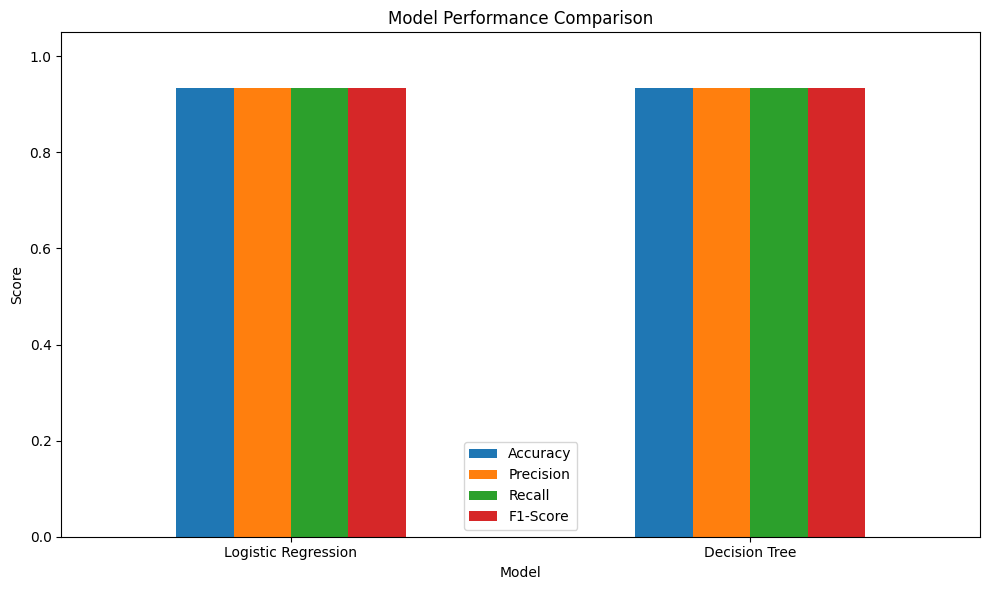

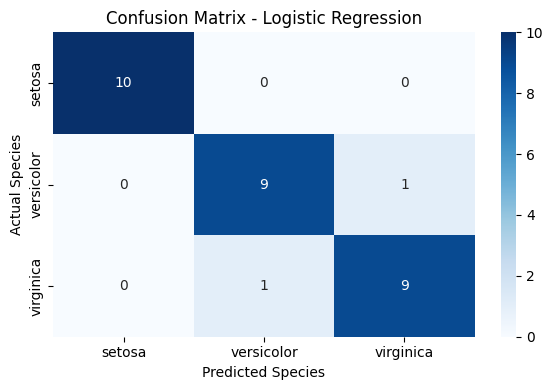

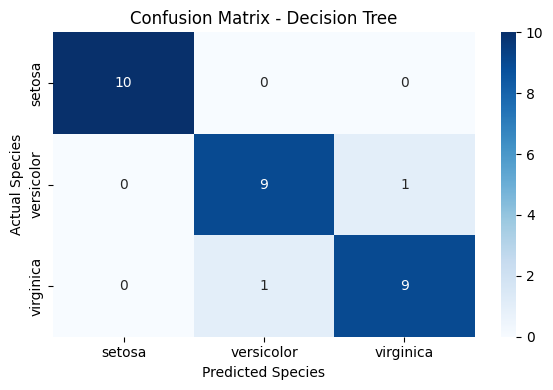

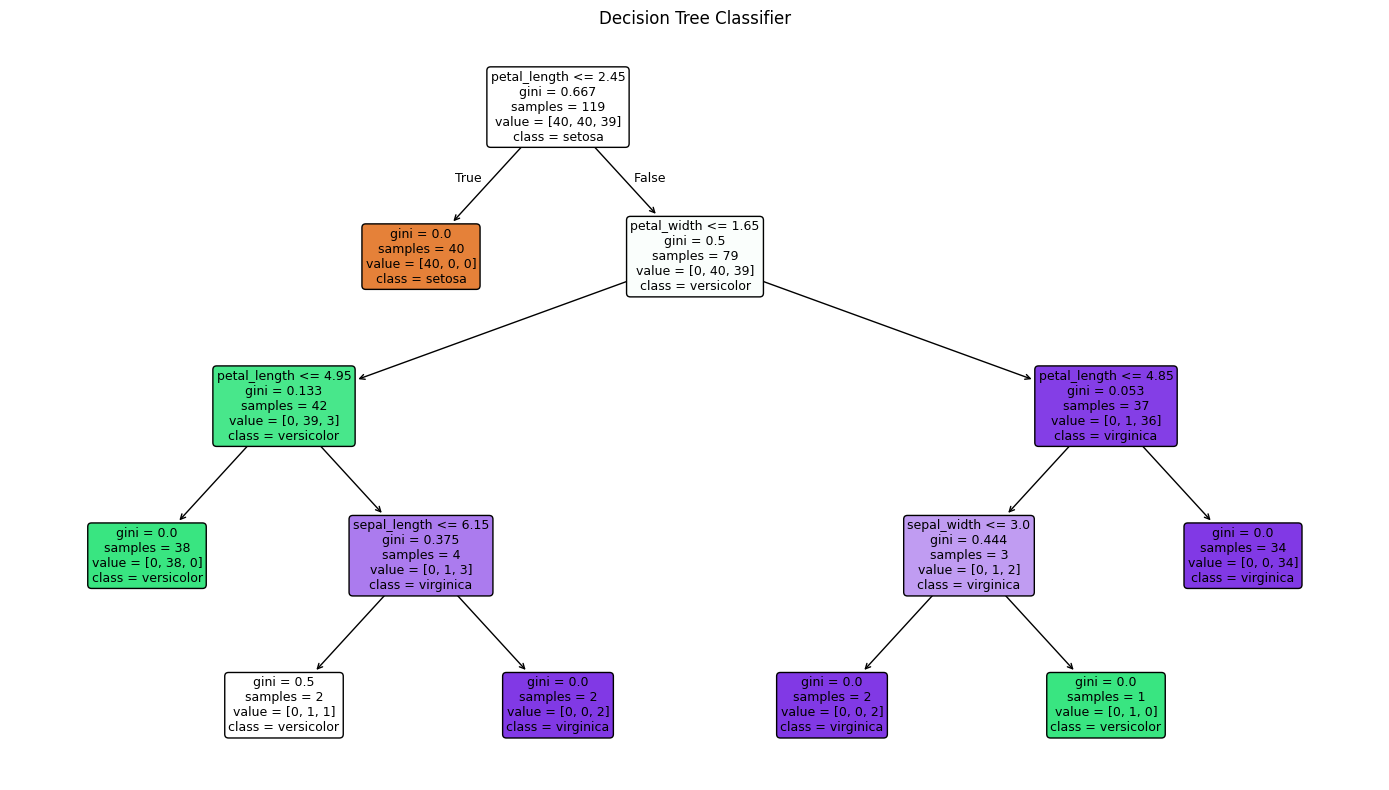


Best Model: Logistic Regression
New Flower Measurements:


,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2


Predicted Species: setosa

MULTI-CLASS CLASSIFICATION BENCHMARK
Dataset rows used: 149
Number of features: 4
Number of classes: 3
Models evaluated: 2
Best model: Logistic Regression
Best accuracy: 93.33%
Task 1 Completed Successfully!

Cleaned Excel file created.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Program: Multi-Class Classification Benchmark Pipeline
# Dataset: Iris Flower Classification
# Input: Excel file (.xlsx)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

# 1. Upload Excel Dataset
print("Upload your Iris Excel file (.xlsx)")
uploaded = files.upload()

filename = next(iter(uploaded))

# Read the first sheet of Excel file
df = pd.read_excel(filename, sheet_name=0)

# Fix for CSV-like formatting within Excel (single column with commas)
if df.shape[1] == 1 and ',' in str(df.columns[0]):
    col_name = df.columns[0]
    headers = [c.strip().lower() for c in col_name.split(',')]
    # Split the single column by comma into multiple columns
    temp_df = df[col_name].astype(str).str.split(',', expand=True)
    if temp_df.shape[1] == len(headers):
        temp_df.columns = headers
        df = temp_df

# Clean column names
df.columns = df.columns.astype(str).str.strip().str.lower()

# Standardize common Iris column names
rename_columns = {
    "sepallength": "sepal_length",
    "sepal length": "sepal_length",
    "sepalwidth": "sepal_width",
    "sepal width": "sepal_width",
    "petallength": "petal_length",
    "petal length": "petal_length",
    "petalwidth": "petal_width",
    "petal width": "petal_width",
    "class": "species",
    "variety": "species"
}

df = df.rename(columns=rename_columns)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Shape:", df.shape)
print("\nColumn Names:", df.columns.tolist())
print("\nMissing Values:")
print(df.isnull().sum())

# 2. Clean Dataset
df = df.drop_duplicates().copy()

# Required columns
feature_columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width"
]
target_column = "species"

missing_columns = [
    col for col in feature_columns + [target_column]
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}. "
        "Excel file mein four flower measurements aur species column "
        "hona chahiye."
    )

# Convert measurements to numeric
for col in feature_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df[target_column] = df[target_column].astype("string").str.strip().str.lower()

# Remove missing or invalid rows
df = df.dropna(subset=feature_columns + [target_column]).copy()
df = df[df[target_column] != ""].copy()

print("\nCleaned Dataset Shape:", df.shape)
print("\nSpecies Count:")
print(df[target_column].value_counts())

if df[target_column].nunique() < 2:
    raise ValueError("Classification ke liye kam se kam 2 species chahiye.")

# 3. Exploratory Data Analysis (EDA)

# Species distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="species")
plt.title("Iris Species Distribution")
plt.xlabel("Species")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Pairplot
sns.pairplot(df[feature_columns + [target_column]], hue=target_column)
plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    df[feature_columns].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# 4. Separate Features and Target
X = df[feature_columns]
y = df[target_column]

# 5. Split Dataset: 80% Train, 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# 6. Create Classification Models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=4
    )
}

# 7. Train and Evaluate Models
results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

    print(f"\nClassification Report: {name}")
    print(classification_report(
        y_test, y_pred, zero_division=0
    ))

# 8. Compare Models
results_df = pd.DataFrame(results).sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("\nModel Comparison:")
display(results_df.round(3))

# Accuracy comparison graph
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(10, 6), ylim=(0, 1.05))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 9. Confusion Matrix Heatmaps
for name, y_pred in predictions.items():
    model = models[name]
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=model.classes_
    )

    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=model.classes_,
        yticklabels=model.classes_
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Species")
    plt.ylabel("Actual Species")
    plt.tight_layout()
    plt.show()

# 10. Decision Tree Visualization
tree_model = models["Decision Tree"]

plt.figure(figsize=(14, 8))
plot_tree(
    tree_model,
    feature_names=feature_columns,
    class_names=tree_model.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree Classifier")
plt.tight_layout()
plt.show()

# 11. Predict a New Flower
new_flower = pd.DataFrame([{
    "sepal_length": 5.1,
    "sepal_width": 3.5,
    "petal_length": 1.4,
    "petal_width": 0.2
}])

best_name = results_df.iloc[0]["Model"]
best_model = models[best_name]

prediction = best_model.predict(new_flower)[0]

print("\nBest Model:", best_name)
print("New Flower Measurements:")
display(new_flower)
print("Predicted Species:", prediction)

# 12. Final Summary
print("\n" + "=" * 45)
print("MULTI-CLASS CLASSIFICATION BENCHMARK")
print("=" * 45)
print("Dataset rows used:", len(df))
print("Number of features:", len(feature_columns))
print("Number of classes:", y.nunique())
print("Models evaluated:", len(models))
print("Best model:", best_name)
print(f"Best accuracy: {results_df.iloc[0]['Accuracy'] * 100:.2f}%")
print("=" * 45)
print("Task 1 Completed Successfully!")

# 13. Optional: Download cleaned data as Excel
df.to_excel("cleaned_iris_dataset.xlsx", index=False)
print("\nCleaned Excel file created.")
files.download("cleaned_iris_dataset.xlsx")

# New Section